# V-01: Calcium-reporter schematic

**Task:** Create an original teaching visual of calcium-associated GCaMP reporting.

**Inputs:** The three-panel storyboard and primary-reference notes.

**Motivation:** Explain the reporter principle clearly.

**Goal:** Produce an editable storyboard and looping animation.

**Prediction:** The storyboard will connect calcium-associated interaction with a brighter reporter state under excitation.

In [1]:
from pathlib import Path
import hashlib, json, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from matplotlib.patches import Circle, FancyArrowPatch, Ellipse
from PIL import Image
import io

# Locate the shared data folder when Jupyter starts inside a task folder.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data/input").is_dir() and (p / "tasks").is_dir())
INPUT = ROOT / "data/input"
OUTPUT = ROOT / "data/output/V-01"
OUTPUT.mkdir(parents=True, exist_ok=True)
STORYBOARD_FILE = INPUT / "gcamp_storyboard.json"
REFERENCES_FILE = INPUT / "gcamp_primary_references.md"
INPUT_FILES = [STORYBOARD_FILE, REFERENCES_FILE]
BACKGROUND = "#FFFFFF"
plt.rcParams.update({"font.size": 9, "font.family": "DejaVu Sans",
    "axes.spines.top": False, "axes.spines.right": False,
    "savefig.dpi": 300, "svg.fonttype": "none"})


## Materials and methods

Draw cpGFP, calmodulin (CaM) and M13 as labelled domains. Show calcium-associated CaM-M13 interaction and green emission under excitation. Create the artwork with Matplotlib and export SVG, PNG and a three-frame GIF using the storyboard durations. Reference: Chen et al. (2013), https://doi.org/10.1038/nature12354.

**Scope and working assumptions.** The artwork is a conceptual GCaMP-family explanation based on the supplied storyboard and primary reference. Domain geometry, calcium-symbol count, brightness and timing are presentation choices. The visual illustrates calcium-associated reporting, rather than a molecular trajectory or a measured response of the tested clone.

In [2]:
story = json.loads(STORYBOARD_FILE.read_text(encoding="utf-8"))
assert len(story["panels"]) == 3 and len(story["duration_ms"]) == 3
def draw_panel(ax, panel):
    ax.set(xlim=(0, 10), ylim=(0, 6), aspect="equal")
    ax.axis("off")
    color = "#009E73" if panel["brighter"] else "#B8DCCB"
    ax.add_patch(Ellipse((4.4, 3), 2.7, 2.5, fc=color, ec="#335C4E", lw=1.2))
    ax.text(4.4, 3, "cpGFP", ha="center", va="center", fontsize=11)
    ax.add_patch(Circle((7.0, 3.5), 0.85, fc="#D9EAF4", ec="#0072B2"))
    ax.text(7.0, 3.5, "CaM", ha="center", va="center")
    ax.add_patch(Ellipse((6.6, 1.7), 1.5, 0.7, fc="#FAE1A6", ec="#A16B00"))
    ax.text(6.6, 1.7, "M13", ha="center", va="center")
    ax.plot([5.5, 6.2], [3.7, 3.8], c="#555555")
    ax.plot([5.4, 6.1], [2.2, 1.9], c="#555555")
    if panel["calcium_symbol"]:
        ax.add_patch(Circle((8.4, 4.5), 0.38, fc="#E69F00", ec="#9A6500"))
        ax.text(8.4, 4.5, "Ca2+", ha="center", va="center", fontsize=8)
        ax.add_patch(FancyArrowPatch((7.7, 4.4), (7.35, 4.0), arrowstyle="-", ls=":", color="#555555"))
        ax.plot([7.0, 6.8], [2.65, 2.1], color="#555555", ls=":")
        ax.text(8.2, 2.1, "CaM-M13\ninteraction", ha="center", fontsize=8)
    ax.annotate("Excitation", xy=(3.1, 3.1), xytext=(0.2, 4.0),
                arrowprops=dict(arrowstyle="->", color="#0072B2"), color="#0072B2")
    if panel["brighter"]:
        ax.annotate("Green emission", xy=(4.9, 4.1), xytext=(3.5, 5.2),
                    arrowprops=dict(arrowstyle="<-", color="#009E73"), color="#00734F")
    ax.set_title(panel["heading"], fontsize=10, pad=4)
    ax.text(5, 0.3, "Schematic - not to scale", ha="center", fontsize=8, color="#555555")
frames = []
for panel in story["panels"]:
    fig, ax = plt.subplots(figsize=(5.0, 3.3))
    draw_panel(ax, panel)
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=150, facecolor=BACKGROUND)
    buffer.seek(0)
    frames.append(Image.open(buffer).convert("RGB"))
    plt.close(fig)
frames[0].save(OUTPUT / "calcium_reporter.gif", save_all=True, append_images=frames[1:],
               duration=story["duration_ms"], loop=0)
pd.DataFrame(story["panels"]).assign(duration_ms=story["duration_ms"]).to_csv(OUTPUT / "storyboard.csv", index=False)


## Results

Created a three-panel original schematic and a looping teaching animation.

,Output,Format,Input data,Finished without more wet-lab data?
0,Storyboard,PNG + SVG,gcamp_storyboard.json,Yes: conceptual visual
1,Animation,GIF,gcamp_storyboard.json,Yes: conceptual visual


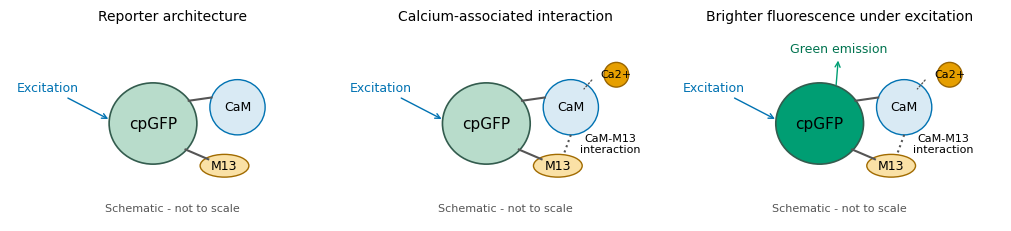

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.0), constrained_layout=True)
for ax, panel in zip(axes, story["panels"]):
    draw_panel(ax, panel)
fig.savefig(OUTPUT / "reporter_storyboard.png", dpi=300)
fig.savefig(OUTPUT / "reporter_storyboard.svg")
display(Markdown("## Results\n\nCreated a three-panel original schematic and a looping teaching animation."))
display(pd.DataFrame({"Output": ["Storyboard", "Animation"], "Format": ["PNG + SVG", "GIF"],
    "Input data": ["gcamp_storyboard.json"] * 2,
    "Finished without more wet-lab data?": ["Yes: conceptual visual"] * 2}))
display(fig)
plt.close(fig)
summary = {
 "title": "V-01: Calcium-associated reporter schematic",
 "question": "How can the reporter principle be explained without claiming a molecular trajectory?",
 "materials": ["Existing three-panel storyboard; Chen et al. (2013) primary GCaMP6 study."],
 "methods": ["Draw cpGFP, CaM and M13 as labelled conceptual domains. Show calcium-associated CaM-M13 interaction and emission under excitation.",
             "Export original SVG/PNG artwork and a looping GIF using the storyboard's presentation durations."],
 "results": [f"Created {len(story['panels'])} panels and an animation lasting {sum(story['duration_ms']) / 1000:g} presentation seconds per loop."],
 "conclusion": "The completed visual presents calcium-associated CaM-M13 interaction and reporter emission in three panels. Editable SVG and PNG files accompany a GIF with a 12-second presentation loop.",
 "limitations": [],
 "figures": [{"file": "reporter_storyboard.png", "caption": "Original conceptual GCaMP-family storyboard. Domain geometry, calcium-symbol count, brightness and animation timing are illustrative, not structural or kinetic results."}],
 "references": ["Chen et al. (2013), Ultrasensitive fluorescent proteins for imaging neuronal activity. https://doi.org/10.1038/nature12354"],
 "table": {"columns": ["Output", "Format", "Scope", "Input data", "Finished without more wet-lab data?"], "rows": [["Storyboard", "PNG + SVG", "Editable original schematic", "Storyboard", "Yes: conceptual"], ["Animation", "GIF", "Three presentation states", "Storyboard", "Yes: conceptual"]]}}
summary["scope_and_assumptions"] = 'The artwork is a conceptual GCaMP-family explanation based on the supplied storyboard and primary reference. Domain geometry, calcium-symbol count, brightness and timing are presentation choices. The visual illustrates calcium-associated reporting, rather than a molecular trajectory or a measured response of the tested clone.'
summary.pop("limitations", None)
(OUTPUT / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8");

In [4]:
display(Markdown("## Conclusion and interpretation\n\n" + summary["conclusion"]))
(OUTPUT / "conclusion.md").write_text(summary["conclusion"], encoding="utf-8")
# Record the source bytes and software used for this calculation.
provenance = {"inputs": {p.name: hashlib.sha256(p.read_bytes()).hexdigest()
                           for p in INPUT_FILES},
    "python": platform.python_version(), "numpy": np.__version__,
    "pandas": pd.__version__, }
(OUTPUT / "provenance.json").write_text(json.dumps(provenance, indent=2), encoding="utf-8");

## Conclusion and interpretation

The completed visual presents calcium-associated CaM-M13 interaction and reporter emission in three panels. Editable SVG and PNG files accompany a GIF with a 12-second presentation loop.